In [103]:
import os
os.environ.pop("PYTHONPATH", None)

import sys
sys.path = [
    p for p in sys.path
    if "/opt/software-current/" not in p
]

import regex
print("regex:", regex.__file__)

regex: /mnt/home/linpaul1/Documents/SPROUT/.venv/lib/python3.13/site-packages/regex/__init__.py


In [104]:
import pandas as pd

df = pd.read_csv("images.csv").fillna("")

In [105]:
import torch
from transformers import AutoModel, AutoProcessor
from PIL import Image
import torch.nn.functional as F

MODEL_NAME = "google/siglip2-base-patch16-224"

device = "cuda" if torch.cuda.is_available() else "cpu"

model = AutoModel.from_pretrained(MODEL_NAME).to(device).eval()
processor = AutoProcessor.from_pretrained(MODEL_NAME)


def embed(image_path: str):
    image = Image.open(image_path).convert("RGB")
    inputs = processor(images=image, return_tensors="pt").to(device)

    with torch.inference_mode():
        output = model.get_image_features(**inputs)
        embedding = output.pooler_output
        embedding = F.normalize(embedding, p=2, dim=-1)

    return embedding.squeeze(0)

def embed_text(text: str):
    inputs = processor(text=[text],
        padding="max_length", return_tensors="pt").to(device)

    with torch.inference_mode():
        output = model.get_text_features(**inputs)
        embedding = output.pooler_output
        embedding = F.normalize(embedding, p=2, dim=-1)

    return embedding.squeeze(0)

Loading weights: 100%|██████████| 408/408 [00:00<00:00, 39625.71it/s]


In [106]:
image_embeddings = torch.stack([
    embed(str(row["image_path"])).squeeze(0).cpu()
    for _, row in df.iterrows()
]).cpu().numpy()

caption_embeddings = torch.stack([
    embed_text(str(caption)).cpu()
    for caption in df["caption"]
]).cpu().numpy()

query = "laptop"

query_embedding = embed_text(query).cpu().numpy()

image_scores = image_embeddings @ query_embedding
caption_scores = caption_embeddings @ query_embedding

combined_scores = (
    .7 * image_scores
    + (1 - .3) * caption_scores
)

df[f"score_combined_{query}"] = combined_scores

# Evaluation

In [107]:
ranked = df.sort_values(f"score_combined_{query}", ascending=False)
relevant = ranked["label"].astype(bool).to_numpy()

n_relevant = relevant.sum()
top_k = relevant[:10]

precision_k = top_k.sum() / len(top_k) if len(top_k) else 0
recall_k = top_k.sum() / n_relevant if n_relevant else 0

precisions = [
    relevant[:i + 1].sum() / (i + 1)
    for i in range(len(relevant))
    if relevant[i]
]

ap = sum(precisions) / n_relevant if n_relevant else 0

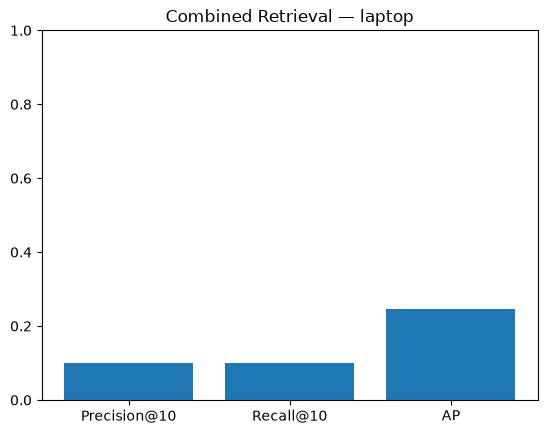

In [108]:
import matplotlib.pyplot as plt

plt.bar(
    ["Precision@10", "Recall@10", "AP"],
    [precision_k, recall_k, ap]
)
plt.title(f"Combined Retrieval — {query}")
plt.ylim(0, 1)
plt.show()

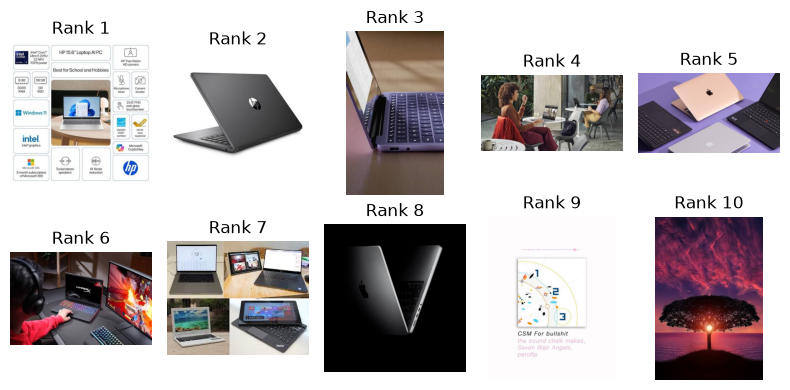

In [109]:
ranked = df.sort_values(
    f"score_combined_{query}",
    ascending=False
).reset_index(drop=True)

top10 = ranked.head(10)

fig, axes = plt.subplots(2, 5, figsize=(8, 4))

for i, ax in enumerate(axes.flat):
    ax.imshow(Image.open(top10.iloc[i]["image_path"]))
    ax.set_title(f"Rank {i + 1}")
    ax.axis("off")

plt.tight_layout()
plt.show()